# Titanic Mini EDA: Task 3
### Data Science / Data Analysis with Python Internship, Main Crafts Technology

**Workflow:** Load → Clean → Analyze → Visualize → Conclude

In Task 2 we looked at survival by gender and class. Here we go deeper with a **Mini Exploratory Data Analysis (EDA)**: better missing-value handling, `groupby` insights by **age group**, **embarkation port** and **family size**, and more advanced visuals (histogram, correlation heatmap, family-size bar plot).

Dataset: Kaggle Titanic `train.csv` (891 passengers).

## 1. Load Dataset

`train.csv` is downloaded from the [Kaggle Titanic competition page](https://www.kaggle.com/c/titanic/data). If the file is not already in the working folder, Colab will prompt you to upload it.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
os.makedirs('visuals', exist_ok=True)

# train.csv downloaded from Kaggle: https://www.kaggle.com/c/titanic/data
DATA_PATH = 'train.csv'
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()  # select train.csv when prompted

df = pd.read_csv(DATA_PATH)
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print("Shape of dataset:", df.shape)
df.info()

Shape of dataset: (891, 12)
<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


## 2. Clean Dataset

Real-world data is rarely complete. We first measure what is missing, then decide how to treat each column.

In [3]:
# Missing values before cleaning
print("Missing values before cleaning:")
print(df.isnull().sum()[df.isnull().sum() > 0])

Missing values before cleaning:
Age         177
Cabin       687
Embarked      2
dtype: int64


**Observation:** `Age` is missing for 177 passengers, `Cabin` for 687 (about 77% of rows) and `Embarked` for 2. Our plan:
- **Age** → fill with the **mean** age, so we keep all 891 passengers.
- **Cabin** → drop; too sparse to be useful.
- **Ticket** → drop; ticket codes carry no analytical value here.
- **Embarked** → fill the 2 gaps with the most common port (mode).

In [4]:
# Fill missing Age with the mean
df['Age'] = df['Age'].fillna(df['Age'].mean())

# Fill missing Embarked with the most common port
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])

# Drop irrelevant columns
df = df.drop(columns=['Cabin', 'Ticket'])

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Mean age used for imputation:", round(df['Age'].mean(), 2))
df.head()

Missing values after cleaning: 0
Duplicate rows: 0
Mean age used for imputation: 29.7


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,8.0500,S


**Observation:** The dataset is now complete: no missing values and no duplicates. One caveat: filling 177 ages with the mean (about 29.7) pulls many passengers to the same value, which slightly narrows the age distribution. We keep this in mind when reading the age charts.

## 3. Analysis Questions

Using `groupby`, we answer three questions about who survived.

### 3.1 Survival rate by Age Group

In [5]:
# Create age groups
df['AgeGroup'] = pd.cut(
    df['Age'],
    bins=[0, 12, 18, 30, 50, 80],
    labels=["Child", "Teen", "YoungAdult", "Adult", "Senior"]
)

survival_by_age = df.groupby('AgeGroup', observed=True)['Survived'].agg(survival_rate='mean', passengers='count')
survival_by_age['survival_rate'] = (survival_by_age['survival_rate'] * 100).round(1)
print(survival_by_age)

            survival_rate  passengers
AgeGroup                             
Child                58.0          69
Teen                 42.9          70
YoungAdult           33.1         447
Adult                42.3         241
Senior               34.4          64


**Insight:** Children (0-12) had the highest survival rate at about **58%**, while young adults (18-30) had the lowest at about **33%**. This supports the "children first" evacuation pattern. Note that the YoungAdult group is the largest (447 passengers) partly because mean-imputed ages (29.7) fall into it.

### 3.2 Survival rate by Embarkation Port

In [6]:
port_names = {'C': 'Cherbourg', 'Q': 'Queenstown', 'S': 'Southampton'}
df['EmbarkedPort'] = df['Embarked'].map(port_names)

survival_by_port = df.groupby('EmbarkedPort')['Survived'].agg(survival_rate='mean', passengers='count')
survival_by_port['survival_rate'] = (survival_by_port['survival_rate'] * 100).round(1)
print(survival_by_port.sort_values('survival_rate', ascending=False))

print()
print("Share of each passenger class by port (%):")
print((pd.crosstab(df['EmbarkedPort'], df['Pclass'], normalize='index') * 100).round(0))

              survival_rate  passengers
EmbarkedPort                           
Cherbourg              55.4         168
Queenstown             39.0          77
Southampton            33.9         646

Share of each passenger class by port (%):
Pclass           1     2     3
EmbarkedPort                  
Cherbourg     51.0  10.0  39.0
Queenstown     3.0   4.0  94.0
Southampton   20.0  25.0  55.0


**Insight:** Passengers who boarded at **Cherbourg** survived most (about **55%**), versus about 39% at Queenstown and 34% at Southampton. The class mix explains much of this: about half of Cherbourg's passengers were 1st class, while 94% of Queenstown's were 3rd class. The port itself is probably not the cause; it is a proxy for class.

### 3.3 Survival rate by Family Size (SibSp + Parch)

In [7]:
df['FamilySize'] = df['SibSp'] + df['Parch']

survival_by_family = df.groupby('FamilySize')['Survived'].agg(survival_rate='mean', passengers='count')
survival_by_family['survival_rate'] = (survival_by_family['survival_rate'] * 100).round(1)
print(survival_by_family)

            survival_rate  passengers
FamilySize                           
0                    30.4         537
1                    55.3         161
2                    57.8         102
3                    72.4          29
4                    20.0          15
5                    13.6          22
6                    33.3          12
7                     0.0           6
10                    0.0           7


**Insight:** Passengers travelling **alone** (family size 0) survived at about **30%**, while small families of 1-3 relatives did much better (55-72%). Survival then collapses for families of 4 or more (0-33%). The very large groups (sizes 7 and 10) contain only 6-7 passengers each, so those 0% figures should be read with caution.

## 4. Visualizations

Four charts that tell the story, each followed by a short interpretation.

### 4.1 Age distribution (histogram)

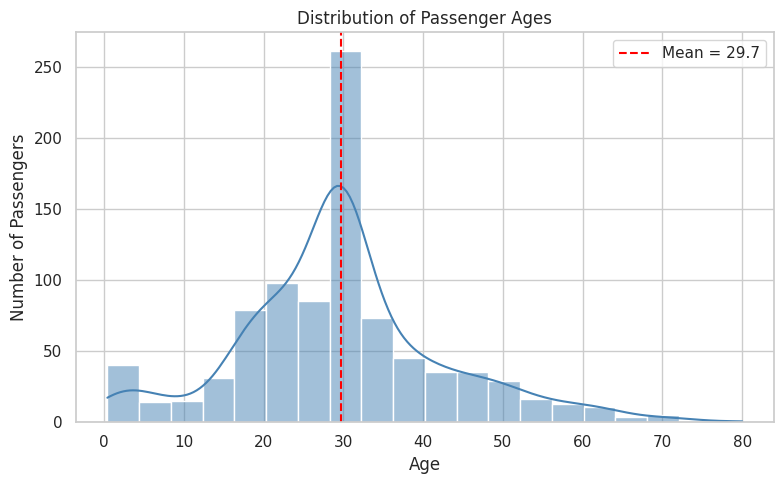

In [8]:
plt.figure(figsize=(8, 5))
sns.histplot(df['Age'], bins=20, kde=True, color='steelblue')
plt.axvline(df['Age'].mean(), color='red', linestyle='--', label=f"Mean = {df['Age'].mean():.1f}")
plt.title('Distribution of Passenger Ages')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')
plt.legend()
plt.tight_layout()
plt.savefig('visuals/histogram_age.png', dpi=150)
plt.show()

**What this shows:** Most passengers were between 20 and 40, with a long tail of older passengers. The tall spike at the mean (about 29.7) is an artefact of our imputation: 177 missing ages were all filled with the same value.

### 4.2 Survival rate by age group (bar plot)

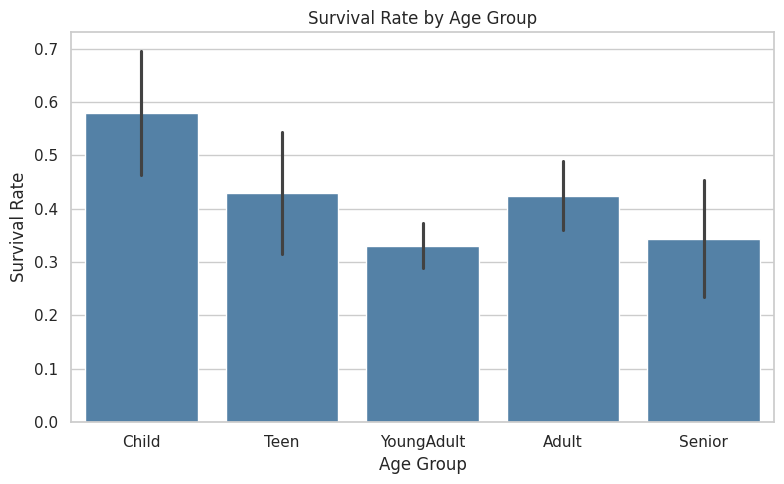

In [9]:
plt.figure(figsize=(8, 5))
sns.barplot(x='AgeGroup', y='Survived', data=df, color='steelblue')
plt.title('Survival Rate by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.savefig('visuals/bar_survival_age_group.png', dpi=150)
plt.show()

**What this shows:** Children had the best odds (about 58%), and young adults the worst (about 33%). The error bars are widest for Child and Senior because those groups are small.

### 4.3 Heatmap of correlations

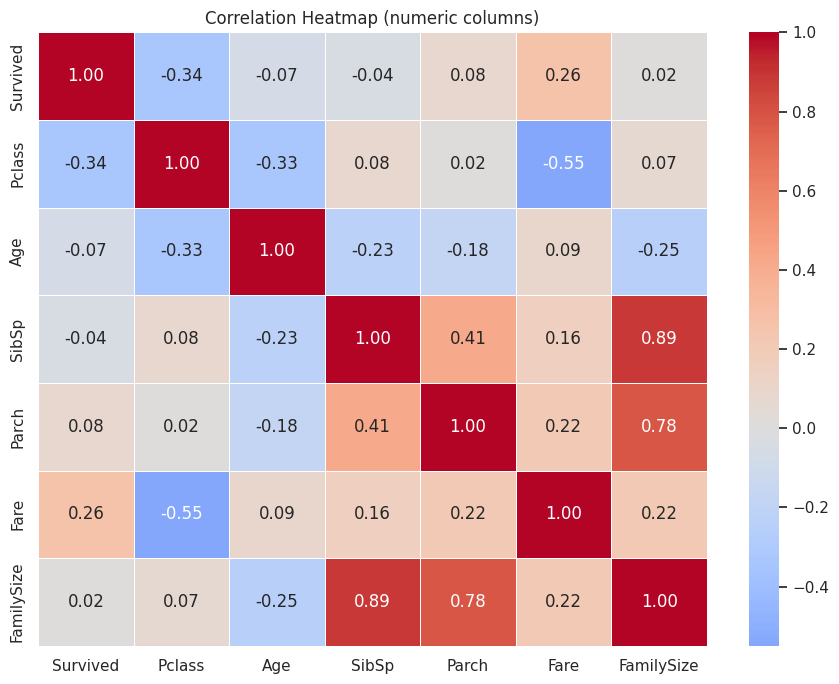

In [10]:
corr_cols = ['Survived', 'Pclass', 'Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']

plt.figure(figsize=(9, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap (numeric columns)')
plt.tight_layout()
plt.savefig('visuals/heatmap_correlations.png', dpi=150)
plt.show()

**What this shows:** The strongest link with survival is **Pclass** (about -0.34: a higher class number means lower survival), followed by **Fare** (about +0.26). `Pclass` and `Fare` are strongly negatively related (about -0.55), which makes sense, since first class cost more. `FamilySize` has almost no *linear* correlation with survival (about 0.02), yet the bar plot below shows a clear pattern, so correlation alone can miss non-linear effects.

### 4.4 Survival by family size (bar plot)

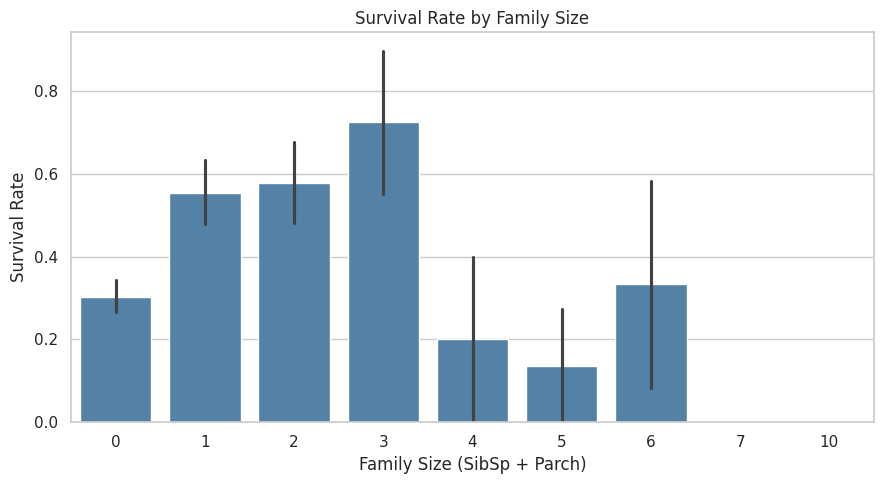

In [11]:
plt.figure(figsize=(9, 5))
sns.barplot(x='FamilySize', y='Survived', data=df, color='steelblue')
plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size (SibSp + Parch)')
plt.ylabel('Survival Rate')
plt.tight_layout()
plt.savefig('visuals/bar_survival_family_size.png', dpi=150)
plt.show()

**What this shows:** Survival rises from about 30% for solo travellers to a peak of about 72% for family size 3, then drops sharply for families of 4 or more. Small families looked after each other; large families were harder to keep together. The wide error bars on the right reflect very few passengers.